# Escenarios: LiST adverso y extremo, la corrida rápida de 2023 y un generador de depositantes

**Pregunta:** ¿Cuánto se mueve el período de supervivencia del banco con la severidad del escenario, con una corrida rápida calibrada antes de 2023 y con la proporción de depósitos no asegurados, y puede una estimación de fuga contrastarse con una simulación cuya verdad se conoce?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- componer un escenario de liquidez a partir de tasas de fuga por segmento con el motor y reconstruir el período de supervivencia de las variantes LiST Adverso y Extremo;
- calibrar una tasa de corrida rápida solo con corridas observadas anteriores a 2023, ver al motor rechazar las filas de 2023 y decir por qué ese rechazo es la guarda de fuga de información del caso;
- correr la grilla de la proporción no asegurada y leer la prueba de monotonía;
- usar un generador de depositantes cuya verdad exacta se conoce para contrastar una estimación de fuga.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
# Etiquetas en español de los semáforos de las pruebas de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `list-adverse.json`, `list-extreme.json` y `fast-run.json`: las tres variantes de trayectoria, cada una con sus segmentos, sus series diarias, su período de supervivencia, su evaluación frente a la corrida de marzo de 2023 y sus sensibilidades.
- `models-svb-liquidity.json`: el documento de modelos, con la calibración de la tasa de la corrida rápida sobre las filas de la Tabla A.1 y la configuración, la verdad exacta y la verificación del generador de depositantes.

Un escenario tiene una familia (idiosincrático, de todo el mercado o combinado) y una fase (aguda, de uno a cinco días, o prolongada, hasta seis a doce meses) (BCBS, 2008, Principio 10); el documento dice qué familia y fase toma cada variante. Todos los archivos están en `data/derived/C16/`; los montos están en miles de USD.

In [2]:
# Cargar los cuatro documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "models-svb-liquidity"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)

adverse, extreme = documents["list-adverse"], documents["list-extreme"]
fast, models = documents["fast-run"], documents["models-svb-liquidity"]
rows = {row["variant"]: row for row in adverse["outputs"]["conventions"]["variant_scenarios"]["rows"]}
for variant, row in rows.items():
    print(f"{variant:14s} horizonte (días): {row['horizon_days']:4d}")

list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-extreme | calculado con riskvalidation 1.0.1 | instalado 1.0.1
fast-run | calculado con riskvalidation 1.0.1 | instalado 1.0.1
models-svb-liquidity | calculado con riskvalidation 1.0.1 | instalado 1.0.1
lcr-standard   horizonte (días):   30
list-adverse   horizonte (días):  125
list-extreme   horizonte (días):  125
fast-run       horizonte (días):    5
htm-losses     horizonte (días):  125


## Método

### Paso 1: los conjuntos de parámetros de LiST

El LiST 2019 del BCE fija la tasa diaria de fuga capitalizada de cada clase de vencimiento abierto bajo tres severidades, Base, Adverso y Extremo (BCE, 2019, nota metodológica, Tabla 3.3). El motor las guarda como `list_scenario(severity)`. Una clase que el conjunto no tiene se rechaza, nunca se mapea en silencio, y los choques de LiST son solo idiosincráticos. La celda siguiente imprime las tasas de las clases que usan los segmentos de C16.

In [3]:
# Las tasas diarias de las clases que usan los segmentos del caso, bajo las tres severidades
from riskvalidation.liquidity.scenarios import list_scenario

classes = ("other-retail", "non-operational-non-financial-corporates", "non-operational-other-financial")
print(f"{'clase':44s}{'Base':>12s}{'Adverso':>12s}{'Extremo':>12s}")
for liquidity_class in classes:
    rates = [list_scenario(severity).class_rate(liquidity_class) for severity in ("baseline", "adverse", "extreme")]
    print(f"{liquidity_class:44s}{rates[0]:12.8f}{rates[1]:12.8f}{rates[2]:12.8f}")

try:
    list_scenario("severe")
except ValueError:
    print("una severidad desconocida se rechaza con un ValueError")

clase                                               Base     Adverso     Extremo
other-retail                                  0.00000000  0.00373218  0.00440873
non-operational-non-financial-corporates      0.00000000  0.00688541  0.01065229
non-operational-other-financial               1.00000000  1.00000000  1.00000000
una severidad desconocida se rechaza con un ValueError


### Paso 2: componer un escenario y su escalera

Un escenario asigna a cada segmento una clase del conjunto de parámetros y un saldo inicial, y guarda su trayectoria de tasas diarias en el horizonte: `compose_scenario(family, phase, parameter_set, segments, horizon)`. Las salidas conductuales son $O_s(d) = B_s \prod_{k<d}(1-q_k)\,q_d$ (notebook 02). La escalera de una variante suma las salidas contractuales del balance (la financiación garantizada que vence) y resta las entradas, sobre la misma capacidad de contrapeso (notebook 03):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \Bigl(\sum_{\text{segments}} O_{\text{seg}}(s) + O_{\text{contractual}}(s) - I(s)\Bigr)$$

La celda siguiente compone los escenarios Adverso y Extremo a partir de los segmentos de cada documento (clase y saldo inicial), con la familia y la fase de las convenciones versionadas, suma los flujos contractuales del documento, e imprime el día de supervivencia de cada variante con el saldo inicial y la primera tasa diaria de cada segmento.

In [4]:
# Componer los escenarios LiST Adverso y Extremo y reconstruir sus escaleras desde los segmentos versionados
from riskvalidation.liquidity.ladder import net_liquidity_position, survival_period
from riskvalidation.liquidity.scenarios import compose_scenario

built = {}
variants = (("list-adverse", "adverse", adverse), ("list-extreme", "extreme", extreme))
words = {"idiosyncratic": "idiosincrática", "protracted": "prolongada", "acute": "aguda"}
for variant, severity, document in variants:
    lad = document["outputs"]["path"]["ladder"]
    row = rows[variant]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    args = (row["scenario_family"], row["phase"], list_scenario(severity))
    scenario = compose_scenario(*args, segments, row["horizon_days"])
    contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
    inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
    total_outflows = scenario.outflows().sum(axis=0) + contractual
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
    built[variant] = (scenario, nlp, survival_period(nlp))
    print(variant, "|", words[scenario.family], words[scenario.phase], "| segmentos:", len(scenario.segments))
    print("   día de supervivencia:", built[variant][2].day)

print(f"{'segmento':28s}{'inicial (mil mill. USD)':>25s}{'tasa Adverso':>14s}{'tasa Extremo':>14s}")
for seg_a, seg_e in zip(built["list-adverse"][0].segments, built["list-extreme"][0].segments):
    print(f"{seg_a.segment_id:28s}{seg_a.opening / 1e6:25.3f}{seg_a.daily_rates[0]:14.8f}{seg_e.daily_rates[0]:14.8f}")

list-adverse | idiosincrática prolongada | segmentos: 3
   día de supervivencia: 62
list-extreme | idiosincrática prolongada | segmentos: 3
   día de supervivencia: 41
segmento                      inicial (mil mill. USD)  tasa Adverso  tasa Extremo
retail-insured                                  9.990    0.00373218    0.00440873
non-operational-corporate                     151.592    0.00688541    0.01065229
financial                                      13.899    1.00000000    1.00000000


Dos cosas destacan. La severidad Extrema acorta el período de supervivencia (mientras más se avanza en la severidad, antes se vuelve negativa la NLP), y el segmento corporativo no asegurado, 151,6 mil millones de 175,5 mil millones de depósitos, domina ambos escenarios: su tasa es 0,00688541 diaria bajo Adverso y 0,01065229 bajo Extremo. El segmento financiero sale completo el día 1 en ambos.

### Paso 3: la corrida rápida, calibrada antes de 2023

La turbulencia de 2023 "reajustó los supuestos de velocidad" (BCBS, 2023). El producto agrega una variante de corrida rápida cuya tasa no es una tabla de LiST sino que se calibra con corridas observadas: la tasa diaria implícita de cada fila $i$ de la Tabla A.1 es $q_i = 1-(1-F_i)^{1/n_i}$ (notebook 02) y la tasa ajustada es un estadístico de esas tasas; la regla de calibración del documento es el máximo (`maximum-implied-daily-rate`, una convención declarada, porque los dosieres no dan un método de calibración). El protocolo sin fuga de información es este: calibrar con las filas anteriores a 2023 y evaluar con las filas de 2023. El motor lo hace cumplir: una llamada marcada `scored=True` rechaza una fila de 2023. La celda siguiente calibra, intenta la llamada rechazada y compara con la calibración versionada. La observación de Silicon Valley Bank (85% en 2 días; Federal Reserve, 2023) entra solo como un ancla rotulada, nunca como un pronóstico.

In [5]:
# Calibrar la tasa de la corrida rápida con las filas anteriores a 2023, probar una fila de 2023 y leer el ancla
from riskvalidation.liquidity.runoff import TABLE_A1
from riskvalidation.liquidity.scenarios import anchor_from_observation, fast_run_scenario

pre_2023 = [run for run in TABLE_A1 if run.year < 2023]
fit = fast_run_scenario(pre_2023, "maximum-implied-daily-rate", scored=True)

print("filas usadas:", [run.row_id for run in pre_2023])
print("tasas diarias implícitas:", [round(q, 6) for q in fit.implied_rates])
print("tasa ajustada (máximo):", round(fit.daily_rate, 8))

try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("una llamada evaluada con una fila de 2023 es rechazada por el motor (ValueError)")

anchor = anchor_from_observation(0.85, 2)
print("ancla: proporción de salida y días:", anchor["outflow_share"], anchor["days"])
print("tasa diaria implícita del ancla:", round(anchor["implied_daily_rate"], 6))
print("el ancla es un pronóstico:", "sí" if anchor["forecast_claim"] else "no")

filas usadas: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
tasas diarias implícitas: [0.002971, 0.054258, 0.010481, 0.005938]
tasa ajustada (máximo): 0.05425839
una llamada evaluada con una fila de 2023 es rechazada por el motor (ValueError)
ancla: proporción de salida y días: 0.85 2
tasa diaria implícita del ancla: 0.612702
el ancla es un pronóstico: no


El escenario de corrida rápida pone la tasa ajustada en el segmento corporativo no asegurado (la única clase que guarda un conjunto de parámetros `FastRun`, `concentrated-uninsured`) y mantiene las tasas de LiST Adverso en los demás segmentos, en el horizonte agudo de 5 días. La celda siguiente lo compone, reconstruye su escalera como en el paso 2, y luego evalúa la variante frente a las corridas de 2023 que su escalera de 5 días alcanza (las filas más allá del horizonte no pueden evaluarse) con la contrastación del producto.

In [6]:
# Componer la corrida rápida: la tasa ajustada en el segmento corporativo no asegurado, LiST Adverso en el resto
from riskvalidation.liquidity.scenarios import Scenario

lad = fast["outputs"]["path"]["ladder"]
row = rows["fast-run"]
family, phase, horizon = row["scenario_family"], row["phase"], row["horizon_days"]
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
others = {k: v for k, v in segments.items() if k != "non-operational-corporate"}
concentrated = {"non-operational-corporate": ("concentrated-uninsured", segments["non-operational-corporate"][1])}
rest = compose_scenario(family, phase, list_scenario("adverse"), others, horizon)
corporate = compose_scenario(family, phase, fit, concentrated, horizon)
by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
fast_scenario = Scenario(family, phase, horizon, tuple(by_id[k] for k in segments))

contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = fast_scenario.outflows().sum(axis=0) + contractual
fast_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
fast_result = survival_period(fast_nlp)

print("NLP de los 5 días (miles de millones de USD):", [round(float(x) / 1e6, 2) for x in fast_nlp])
print("sobrevive el horizonte:", "sí" if fast_result.survives else "no")

NLP de los 5 días (miles de millones de USD): [13.8, 27.42, 34.3, 27.25, 20.57]
sobrevive el horizonte: sí


La corrida rápida se evalúa frente a las corridas de 2023 que alcanza su escalera de 5 días: la proporción modelada es la salida acumulada de los segmentos sobre la base de depósitos del modelo, y la contrastación del producto la pone frente a la proporción que declara la revisión de la Junta y la que respalda el reporte de llamada (las proporciones realizadas de los denominadores del documento).

In [7]:
# Evaluar la corrida rápida frente a las corridas de 2023 que alcanza, y contrastarla en el horizonte de dos días
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

evaluation = fast["outputs"]["scoring"]
base_deposits = evaluation["model_deposit_base"]
outflow_by_day = np.cumsum(fast_scenario.outflows().sum(axis=0))
print(f"{'fila Tabla A.1':22s}{'días':>6s}{'observada':>11s}{'modelada':>10s}")
for run in TABLE_A1:
    if run.year == 2023 and run.days <= fast_scenario.horizon:
        modelled = outflow_by_day[run.days - 1] / base_deposits
        print(f"{run.row_id:22s}{run.days:6d}{run.outflow_share:11.2f}{modelled:10.4f}")

event_days = evaluation["event"]["horizon_days"]
modelled_event = outflow_by_day[event_days - 1] / base_deposits
for board in evaluation["denominators"]:
    test = runoff_adequacy_back_test(
        modelled_event, board["realised_share"], compared_at="event-horizon", denominator=board["id"]
    )
    light = LIGHTS[test.light.value]
    print(f"{board['id']:20s} real {board['realised_share']:.4f} | razón {test.statistic:.6f} | {light}")

fila Tabla A.1          días  observada  modelada
svb-2023                   2       0.85    0.1708
svb-uk-2023                1       0.30    0.1263
signature-2023             1       0.20    0.1263
board-stated-share   real 0.8500 | razón 0.200976 | rojo
call-report-dep      real 0.7983 | razón 0.213999 | rojo


La celda siguiente dibuja la NLP de las tres variantes en un mismo eje: las trayectorias Adversa y Extrema en 125 días y los cinco días de la corrida rápida.

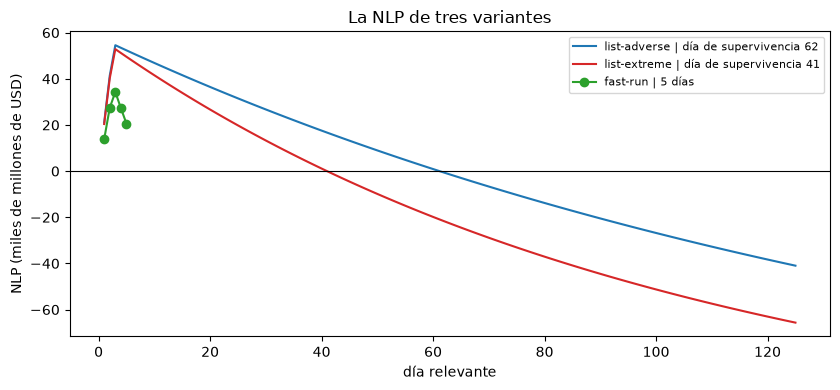

In [8]:
# Dibujar la NLP de las tres variantes: LiST Adverso y Extremo en 125 días, la corrida rápida en sus 5 días
fig, ax = plt.subplots(figsize=(8.5, 4))
for variant, color in (("list-adverse", "tab:blue"), ("list-extreme", "tab:red")):
    nlp_path, result = built[variant][1], built[variant][2]
    label = f"{variant} | día de supervivencia {result.day}"
    ax.plot(np.arange(1, len(nlp_path) + 1), nlp_path / 1e6, color=color, label=label)
ax.plot(np.arange(1, len(fast_nlp) + 1), fast_nlp / 1e6, color="tab:green", marker="o", label="fast-run | 5 días")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("día relevante")
ax.set_ylabel("NLP (miles de millones de USD)")
ax.set_title("La NLP de tres variantes")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La trayectoria Extrema cruza cero el día 41 y la Adversa el día 62: mientras más se avanza en la severidad, antes se vuelve negativa la posición. Los cinco puntos verdes son la corrida rápida, que se mantiene positiva, entre 13,80 y 34,30 mil millones de USD, solo porque su horizonte termina el día 5: su tasa es la más rápida de las tres, pero la escalera es demasiado corta para agotar el CBC. Hay que leer la evaluación anterior con eso en mente: la corrida rápida modela 0,1708 de la base de depósitos en los dos días en que SVB perdió 0,85, una razón de cerca de un quinto, rojo. La figura muestra la NLP, no la plausibilidad de la tasa.

### Paso 4: la grilla de la proporción no asegurada

El riesgo de corrida de un banco sube con la proporción de sus depósitos que nadie asegura (Diamond y Dybvig, 1983, es la teoría; la proporción no asegurada es el motor que el dosier de investigación conserva). `uninsured_share_grid` conserva el total de los dos saldos y mueve una proporción $\sigma$ al no asegurado:

$$\mathrm{uninsured} = (D_{\text{ins}} + D_{\text{unins}})\,\sigma, \qquad \mathrm{insured} = (D_{\text{ins}} + D_{\text{unins}})\,(1-\sigma)$$

Para cada proporción se corre de nuevo la escalera con los nuevos saldos iniciales. El período de supervivencia no debe alargarse al subir la proporción; la prueba `liq.uninsured_share_sensitivity` toma el mayor aumento del período de supervivencia a lo largo de la grilla, en días. La celda siguiente vuelve a correr la escalera en cada proporción de la grilla del documento e imprime el día de supervivencia de cada una, con el resultado de la prueba de monotonía.

In [9]:
# Volver a correr la escalera LiST Adverso en cada proporción no asegurada de la grilla, y probar la monotonía
from riskvalidation.liquidity.scenarios import uninsured_share_grid
from riskvalidation.validation.liquidity import uninsured_share_sensitivity

lad = adverse["outputs"]["path"]["ladder"]
row = rows["list-adverse"]
base = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
shares = [entry["share"] for entry in adverse["outputs"]["sensitivities"]["uninsured_share"]]
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
args = (row["scenario_family"], row["phase"], list_scenario("adverse"))
insured_class, insured_opening = base["retail-insured"]
corporate_class, corporate_opening = base["non-operational-corporate"]

days = []
for insured, uninsured in uninsured_share_grid(insured_opening, corporate_opening, shares):
    openings = dict(base)
    openings["retail-insured"] = (insured_class, insured)
    openings["non-operational-corporate"] = (corporate_class, uninsured)
    scenario = compose_scenario(*args, openings, row["horizon_days"])
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), scenario.outflows().sum(axis=0) + contractual, inflows)
    outcome = survival_period(nlp)
    days.append(None if outcome.survives else outcome.day)

sensitivity = uninsured_share_sensitivity(shares, days)
print("proporciones no aseguradas:", shares)
print("días de supervivencia:", days)
print("mayor aumento en la grilla (días):", sensitivity.statistic, "| semáforo:", LIGHTS[sensitivity.light.value])

proporciones no aseguradas: [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
días de supervivencia: [77, 75, 73, 71, 69, 68, 66, 64, 63, 61]
mayor aumento en la grilla (días): 0.0 | semáforo: verde


La celda siguiente dibuja el período de supervivencia frente a la proporción no asegurada.

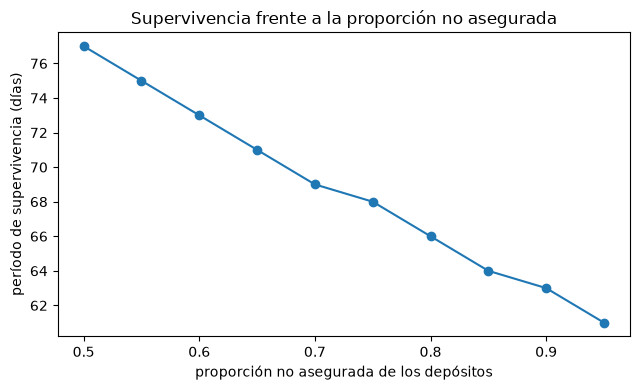

In [10]:
# Dibujar el período de supervivencia de la escalera LiST Adverso frente a la proporción no asegurada
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(shares, days, marker="o", color="tab:blue")
ax.set_xlabel("proporción no asegurada de los depósitos")
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Supervivencia frente a la proporción no asegurada")
fig.tight_layout()
plt.show()

La línea solo baja: de 77 días cuando la mitad de los depósitos no está asegurada a 61 días cuando lo está el 95%, una pérdida de uno a dos días por cada cinco puntos de proporción. Ese es el signo que verifica la prueba, y su mayor aumento a lo largo de la grilla es 0,0 días. La forma es suave porque pasar depósitos del segmento minorista asegurado al corporativo sube la salida solo en la diferencia entre sus dos tasas diarias (0,00373218 y 0,00688541 bajo Adverso), y el segmento financiero, que sale completo el día 1, no cambia. La figura no dice qué proporción tenía realmente el banco; eso viene del reporte de llamada.

### Paso 5: un generador de depositantes con verdad conocida

Una estimación de fuga solo puede probarse contra una verdad conocida. `DepositorGenerator` simula depositantes de varios segmentos mediante una cadena de Markov sistémica de dos estados sobre los días (calma o estrés, una cadena compartida por todos los depositantes); un depositante aún depositado el día $d$ retira con la tasa $h_{\text{calma}}$ o $h_{\text{estrés}}$ del estado de ese día. Como el modelo es pequeño, su verdad es exacta: con $u_d$ el vector fila de probabilidades de seguir depositado en cada estado, $P$ la matriz de transición entre los estados y $\odot$ el producto elemento a elemento,

$$u_1 = (1 - h_{\text{calm}},\; 0), \qquad u_{d+1} = (u_d P) \odot (1 - h_{\text{calm}},\; 1 - h_{\text{stress}}), \qquad F_{\text{truth}}(n) = 1 - \textstyle\sum u_n$$

La ley de transición del estado de estrés (una probabilidad diaria de entrada de 0,01 y una de salida de 0,05) no tiene fuente en los dosieres: es una convención del motor, declarada como tal (UNVERIFIED). Los segmentos, proporciones y tasas de retiro vienen del documento de modelos, que calibró la tasa de retiro de estrés del segmento corporativo con la tasa de la corrida rápida. La celda siguiente reconstruye el generador desde la configuración versionada y calcula su verdad exacta en cuatro horizontes.

In [11]:
# Reconstruir el generador desde la configuración versionada y calcular su verdad exacta
from riskvalidation.liquidity.deposits import DepositorConfig, DepositorGenerator, DepositorSegment

generator_doc = models["fit"]["generator"]
config = generator_doc["config"]
# una sola cadena de estrés es compartida por todos los depositantes: sus dos probabilidades se repiten en cada fila
((p_enter, p_exit),) = {(s["p_enter_stress"], s["p_exit_stress"]) for s in config["segments"]}
segments = tuple(
    DepositorSegment(s["segment"], s["share_of_deposits"], s["calm_daily_hazard"], s["stress_daily_hazard"])
    for s in config["segments"]
)
settings = DepositorConfig(segments, config["n_depositors"], config["horizon_days"], p_enter, p_exit)
generator = DepositorGenerator(settings)
truth = generator.truth()["outflow_rate"]

print("depositantes por segmento y horizonte:", config["n_depositors"], config["horizon_days"])
for key, path in truth.items():
    print(f"{key:28s}", {day: round(float(path[day - 1]), 6) for day in (2, 5, 30, 125)})

depositantes por segmento y horizonte: 1000 125
retail-insured               {2: 3.7e-05, 5: 0.00035, 30: 0.009646, 125: 0.062623}
non-operational-corporate    {2: 0.000543, 5: 0.004852, 30: 0.100707, 125: 0.44551}
financial                    {2: 0.01, 5: 0.039404, 30: 0.252828, 125: 0.712416}


Ahora la contrastación. La estimación es la proporción media de salida acumulada de una muestra con semilla de corridas simuladas, en los horizontes del documento (2, 5, 30 y 125 días); su error estándar de Monte Carlo es la desviación estándar sobre la raíz del número de simulaciones. La prueba `liq.runoff_vs_generator_truth` toma la mayor distancia a la verdad en errores estándar: verde hasta 2, ámbar hasta 3, rojo por encima (compuertas internas del producto). Esta celda usa 2.000 simulaciones, que toman una fracción de segundo.

In [12]:
# Contrastar la fuga simulada con la verdad exacta del generador
from riskvalidation.validation.liquidity import runoff_vs_generator_truth

draws = 2000
rng = np.random.default_rng(42)
samples = {key: np.empty((draws, config["horizon_days"])) for key in truth}
for i in range(draws):
    for key, path in generator.draw(rng)["outflow_rate"].items():
        samples[key][i] = path

horizons = (2, 5, 30, 125)
pairs = [(k, h) for k in truth for h in horizons]
estimated = np.array([samples[k][:, h - 1].mean() for k, h in pairs])
exact_values = np.array([truth[k][h - 1] for k, h in pairs])
standard_errors = np.array([samples[k][:, h - 1].std(ddof=1) / np.sqrt(draws) for k, h in pairs])

check = runoff_vs_generator_truth(estimated, exact_values, standard_errors)
print("simulaciones:", draws, "| comprobaciones:", check.n)
print("mayor distancia en errores estándar:", round(check.statistic, 4), "| semáforo:", LIGHTS[check.light.value])

simulaciones: 2000 | comprobaciones: 12
mayor distancia en errores estándar: 1.3558 | semáforo: verde


La celda siguiente dibuja la verdad exacta del segmento corporativo del generador con las medias simuladas en los cuatro horizontes y sus barras de dos errores estándar.

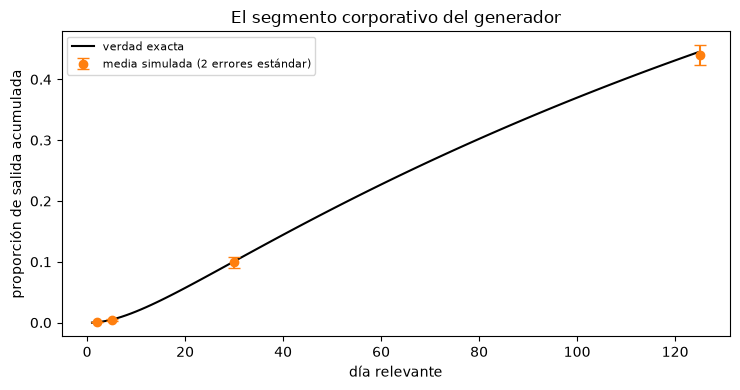

In [13]:
# Dibujar la verdad exacta del segmento corporativo frente a las medias simuladas y sus errores estándar
key = "non-operational-corporate"
position = [pairs.index((key, h)) for h in horizons]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(np.arange(1, 126), truth[key], color="black", label="verdad exacta")
ax.errorbar(
    horizons, estimated[position], yerr=2 * standard_errors[position],
    fmt="o", color="tab:orange", capsize=4, label="media simulada (2 errores estándar)",
)
ax.set_xlabel("día relevante")
ax.set_ylabel("proporción de salida acumulada")
ax.set_title("El segmento corporativo del generador")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La curva negra es la salida acumulada exacta del segmento corporativo, calculada desde la cadena de dos estados: 0,000543 el día 2, 0,004852 el día 5, 0,100707 el día 30 y 0,445510 el día 125. Los puntos naranjas son las medias de 2.000 corridas simuladas con semilla, y toda barra de dos errores estándar contiene la curva; la mayor distancia en las doce comprobaciones es 1,3558 errores estándar, dentro de la compuerta verde de 2. La comprobación dice que el estimador y la aritmética coinciden con un mecanismo conocido exactamente. No dice que el mecanismo se parezca a una corrida real, porque la ley del estado de estrés es una convención del motor.

## Resultados

**Respuesta:** El período de supervivencia cae del día 62 bajo LiST Adverso al día 41 bajo Extremo, y de 77 a 61 días cuando la proporción no asegurada de los depósitos pasa de 0,5 a 0,95. La corrida rápida, calibrada con las cuatro filas anteriores a 2023 a una tasa diaria de 0,05425839, nunca se vuelve negativa en sus 5 días, pero modela solo 0,1708 de la base de depósitos en los dos días en que SVB perdió 0,85 (una razón de 0,200976, rojo). Una simulación de depositantes con verdad exacta queda a 1,3558 errores estándar de ella, lo que vuelve contrastable una estimación de fuga.

- **Composición.** Componer los segmentos con el motor da la NLP negativa el día 62 bajo LiST Adverso y el día 41 bajo Extremo. El segmento corporativo no asegurado (151,592 mil millones de USD, una tasa diaria de 0,00688541 bajo Adverso y 0,01065229 bajo Extremo) domina a ambos, y el segmento financiero (13,899 mil millones) sale completo el día 1.
- **La corrida rápida.** La tasa ajustada con las cuatro filas anteriores a 2023 es 0,05425839 (Northern Rock, 20% en 4 días), y el motor rechaza una fila de 2023 en una llamada evaluada. Con esa tasa la escalera de 5 días nunca se vuelve negativa (la NLP queda entre 13,80 y 34,30 mil millones, su valor más bajo el día 1), así que sobrevive su horizonte. Sin embargo modela 0,1708 de la base de depósitos en los dos días en que SVB perdió 0,85, y 0,1263 en el único día en que SVB UK perdió 0,30 y Signature 0,20. Calibrada solo con lo ocurrido antes de 2023, incluso la tasa más rápida queda muy corta frente a la corrida con la que se evalúa.
- **La proporción no asegurada.** En las diez proporciones de 0,5 a 0,95 el período de supervivencia cae de 77 a 61 días, y la prueba de monotonía es verde con un aumento máximo de 0,0 días.
- **El generador.** La verdad exacta del generador para el segmento corporativo es 0,000543, 0,004852, 0,100707 y 0,445510 a 2, 5, 30 y 125 días. Con 2.000 simulaciones con semilla la mayor distancia a la verdad es 1,3558 errores estándar, verde. La comprobación vale lo que vale el generador: la ley de estrés es una convención, así que prueba la aritmética de un estimador frente a un mecanismo conocido, no el mecanismo frente a la realidad.

Lo que este notebook no muestra: el multiplicador de la fuga con el que el período de supervivencia cae a una meta (notebook 06), ni la comparación de las fugas suave y rápida como pregunta de estado del arte (notebook 07). Todo período de supervivencia pertenece a un comportamiento sintético sobre agregados reales.

## Resumen

- Un escenario es una familia, una fase y, por segmento, una clase y un saldo inicial; el motor compone las tasas diarias y las salidas, y la escalera del documento se reconstruye.
- La tasa de la corrida rápida se calibra solo con las filas anteriores a 2023, y el motor rechaza una fila de 2023 en una llamada evaluada: la división de calibración es una regla del código, no una promesa.
- El período de supervivencia es no creciente en la proporción no asegurada y en la severidad, y las pruebas verifican ambas cosas.
- Un generador con verdad exacta convierte una estimación de fuga en una afirmación contrastable, en errores estándar de Monte Carlo.

**Qué probar a continuación.** Cambia la semilla o el número de simulaciones y mira cómo se mueve la mayor distancia a la verdad; luego sigue con el notebook 05.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155